# Global E-commerce Sales Analysis
### Data Analyst Portfolio Project | Python | Pandas | Matplotlib | Seaborn

**Project objective:** Analyse sales, profit, products, customers, discounts, payment methods and shipping costs using the provided e-commerce dataset.

**Dataset:** `global_ecommerce_sales.csv`  
**Rows and columns:** 2,000 rows × 15 columns (verified from the uploaded dataset).

> Keep this notebook and the CSV file in the same folder. Then run the notebook from top to bottom.

## 1. Import Libraries

We use:
- **Pandas** for data loading, cleaning and analysis.
- **Matplotlib** and **Seaborn** for visualizations.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")

## 2. Load the Dataset

Place `global_ecommerce_sales.csv` in the same folder as this notebook.

In [5]:
df = pd.read_csv(r"C:\Users\purus\OneDrive\Desktop\Project\Data Analytics\01_Dataset\global_ecommerce_sales.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (2000, 15)


,Order_ID,Order_Date,Customer_Name,Customer_Segment,Country,Region,Product_Category,Product_Name,Quantity,Unit_Price,Discount_Percent,Total_Sales,Shipping_Cost,Profit,Payment_Method
0,ORD-11121,2023-01-02,Karen Suzuki,Corporate,United States,North America,Technology,Wireless Bluetooth Headphones,3,99.43,0,298.29,9.31,124.92,Cash on Delivery
1,ORD-11244,2023-01-02,John Johansson,Corporate,Spain,Europe,Technology,Mechanical Gaming Keyboard,4,97.93,20,313.38,14.31,83.62,Cash on Delivery
2,ORD-10325,2023-01-03,Jessica Garcia,Consumer,Mexico,North America,Office Supplies,Binder Clips Assorted 48pc,2,10.74,0,21.48,8.12,3.69,Credit Card
3,ORD-10467,2023-01-03,Clara Taylor,Corporate,Italy,Europe,Technology,Webcam HD 1080p,2,61.86,15,105.16,10.79,26.32,PayPal
4,ORD-11454,2023-01-05,Felix Thomas,Consumer,Italy,Europe,Furniture,Standing Desk Converter,4,330.67,20,1058.14,11.09,253.44,Credit Card


## 3. Understand the Dataset

In [6]:
print("Column names:")
print(df.columns.tolist())

print("\\nDataset information:")
df.info()

print("\\nStatistical summary:")
display(df.describe(include="all").T)

Column names:
['Order_ID', 'Order_Date', 'Customer_Name', 'Customer_Segment', 'Country', 'Region', 'Product_Category', 'Product_Name', 'Quantity', 'Unit_Price', 'Discount_Percent', 'Total_Sales', 'Shipping_Cost', 'Profit', 'Payment_Method']
\nDataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          2000 non-null   str    
 1   Order_Date        2000 non-null   str    
 2   Customer_Name     2000 non-null   str    
 3   Customer_Segment  2000 non-null   str    
 4   Country           2000 non-null   str    
 5   Region            2000 non-null   str    
 6   Product_Category  2000 non-null   str    
 7   Product_Name      2000 non-null   str    
 8   Quantity          2000 non-null   int64  
 9   Unit_Price        2000 non-null   float64
 10  Discount_Percent  2000 non-null   int64  
 11  Total_Sales       2000 n

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order_ID,2000,2000,ORD-11121,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_Date,2000,907,2023-12-11,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Name,2000,1534,Chen Patel,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_Segment,2000,3,Consumer,1006,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,2000,20,Mexico,203,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Region,2000,5,North America,578,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Category,2000,4,Technology,567,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Name,2000,40,Wireless Ergonomic Mouse,67,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,2000.0,NaN,NaN,NaN,3.5575,2.704506,1.0,2.0,3.0,5.0,15.0
Unit_Price,2000.0,NaN,NaN,NaN,73.32949,79.311014,3.03,18.7575,46.42,90.25,472.56


## 4. Data Cleaning

Check missing values and duplicate rows. Convert `Order_Date` into a datetime column so it can be used for time-based analysis.

The uploaded dataset currently has no missing values and no duplicate rows. The checks below are still included so the workflow can be repeated.

In [7]:
print("Missing values before cleaning:")
display(df.isna().sum())

print("Duplicate rows before cleaning:", df.duplicated().sum())

df = df.drop_duplicates().copy()
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")

print("Missing values after cleaning:")
display(df.isna().sum())

print("Date range:", df["Order_Date"].min(), "to", df["Order_Date"].max())

Missing values before cleaning:


Order_ID            0
Order_Date          0
Customer_Name       0
Customer_Segment    0
Country             0
Region              0
Product_Category    0
Product_Name        0
Quantity            0
Unit_Price          0
Discount_Percent    0
Total_Sales         0
Shipping_Cost       0
Profit              0
Payment_Method      0
dtype: int64

Duplicate rows before cleaning: 0
Missing values after cleaning:


Order_ID            0
Order_Date          0
Customer_Name       0
Customer_Segment    0
Country             0
Region              0
Product_Category    0
Product_Name        0
Quantity            0
Unit_Price          0
Discount_Percent    0
Total_Sales         0
Shipping_Cost       0
Profit              0
Payment_Method      0
dtype: int64

Date range: 2023-01-02 00:00:00 to 2025-12-31 00:00:00


## 5. Analysis 1 — Total Sales by Region

**Question:** Which region generates the highest total sales?

**Business use:** Helps compare regional sales performance.

Region
Europe                  137006.20
North America           133876.38
Asia Pacific            121707.51
South America            46051.13
Middle East & Africa     45918.12
Name: Total_Sales, dtype: float64

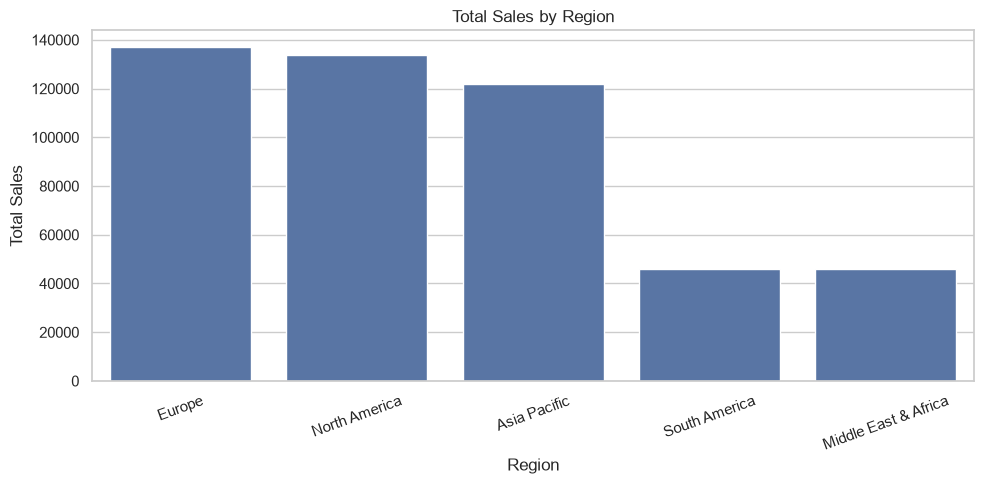

In [8]:
region_sales = df.groupby("Region")["Total_Sales"].sum().sort_values(ascending=False)
display(region_sales)

plt.figure(figsize=(10, 5))
sns.barplot(x=region_sales.index, y=region_sales.values)
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 6. Analysis 2 — Top 10 Products by Profit

**Question:** Which 10 products generate the highest total profit?

**Business use:** Helps identify products that contribute strongly to profitability.

Product_Name
Ergonomic Office Chair           15104.58
Standing Desk Converter          14694.35
Corner L-Shaped Desk             13663.00
Mesh Back Task Chair             12820.11
Wireless Bluetooth Headphones    10611.08
Mechanical Gaming Keyboard        8381.19
Filing Cabinet 3-Drawer           7041.80
Portable External SSD 1TB         6556.75
Business Casual Blazer            6004.33
Noise Cancelling Earbuds          5973.01
Name: Profit, dtype: float64

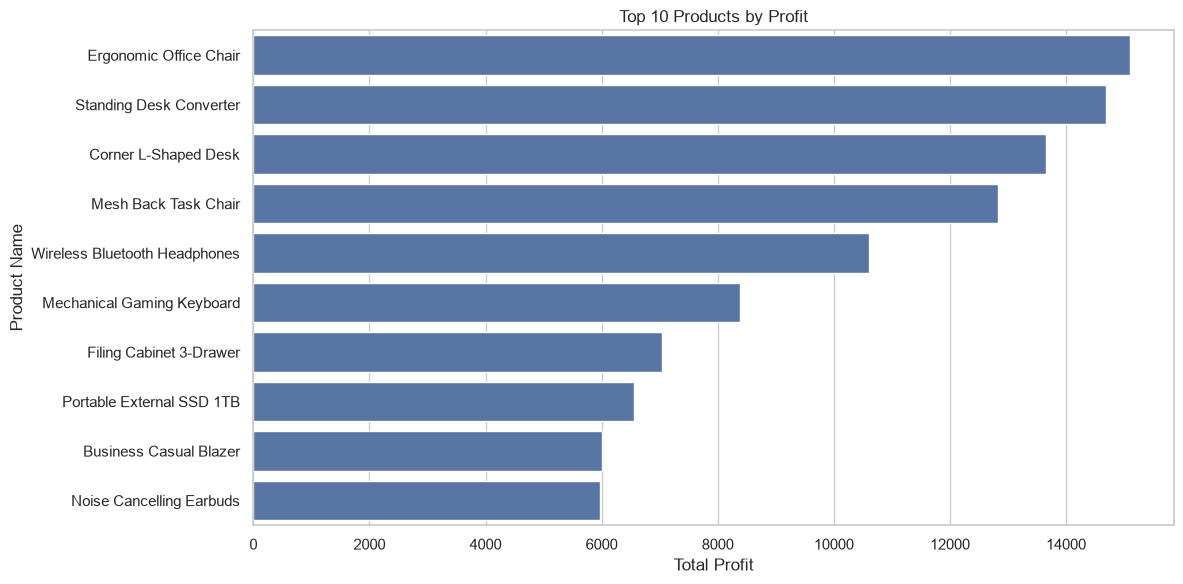

In [9]:
top_products_profit = (
    df.groupby("Product_Name")["Profit"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)
display(top_products_profit)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_products_profit.values, y=top_products_profit.index)
plt.title("Top 10 Products by Profit")
plt.xlabel("Total Profit")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()

## 7. Analysis 3 — Profit by Product Category

**Question:** Which product category generates the highest total profit?

**Business use:** Helps compare the profitability of product categories.

Product_Category
Furniture                 81171.57
Technology                48268.65
Clothing & Accessories    26112.94
Office Supplies            3319.16
Name: Profit, dtype: float64

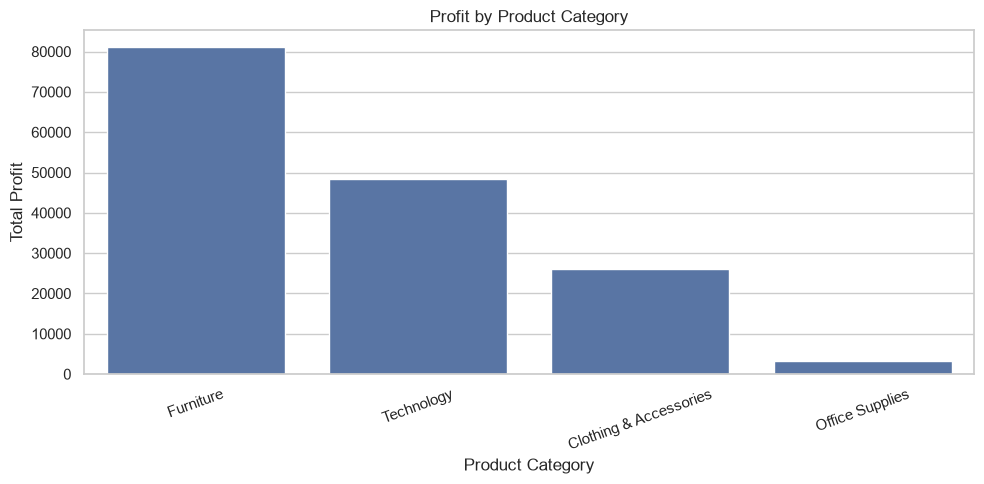

In [10]:
category_profit = (
    df.groupby("Product_Category")["Profit"]
      .sum()
      .sort_values(ascending=False)
)
display(category_profit)

plt.figure(figsize=(10, 5))
sns.barplot(x=category_profit.index, y=category_profit.values)
plt.title("Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 8. Analysis 4 — Monthly Sales Trend

**Question:** How do sales change month by month?

**Business use:** Helps identify growth, declines and seasonal patterns.

Order_Date
2023-01-01    11275.20
2023-02-01    16943.67
2023-03-01    16056.45
2023-04-01    12185.00
2023-05-01     8218.47
2023-06-01    16191.61
2023-07-01    15667.73
2023-08-01    12971.07
2023-09-01    11989.72
2023-10-01    17794.60
2023-11-01     8475.49
2023-12-01    16674.44
Freq: MS, Name: Total_Sales, dtype: float64

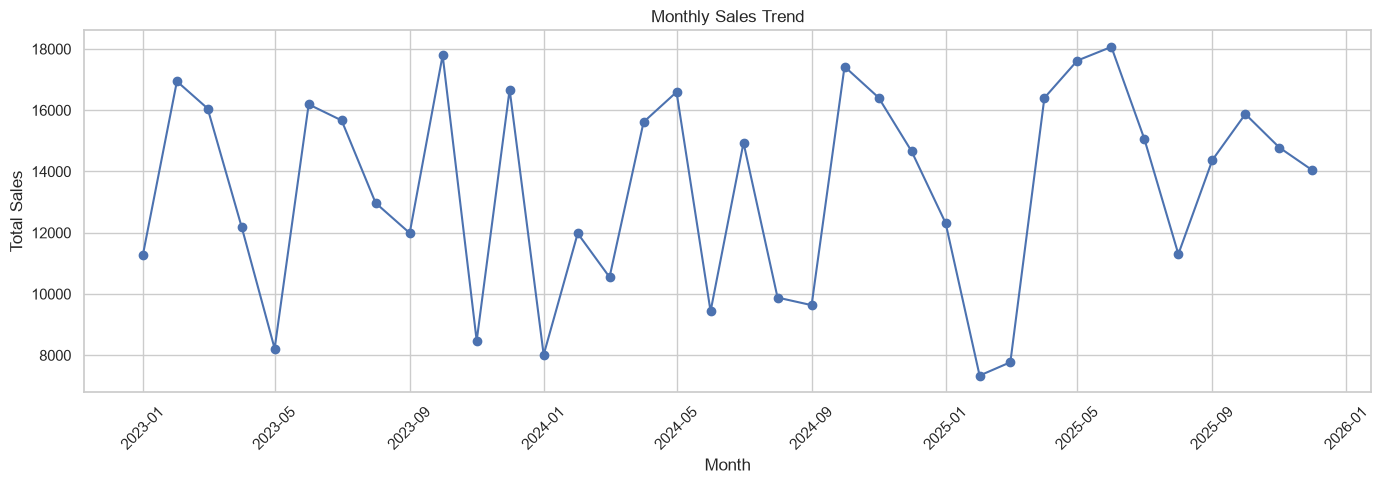

In [11]:
monthly_sales = (
    df.set_index("Order_Date")
      .resample("MS")["Total_Sales"]
      .sum()
)
display(monthly_sales.head(12))

plt.figure(figsize=(14, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 9. Analysis 5 — Sales by Customer Segment

**Question:** Which customer segment contributes the most sales?

**Business use:** Helps understand the value of each customer segment.

Customer_Segment
Consumer       256287.74
Corporate      146050.39
Home Office     82221.21
Name: Total_Sales, dtype: float64

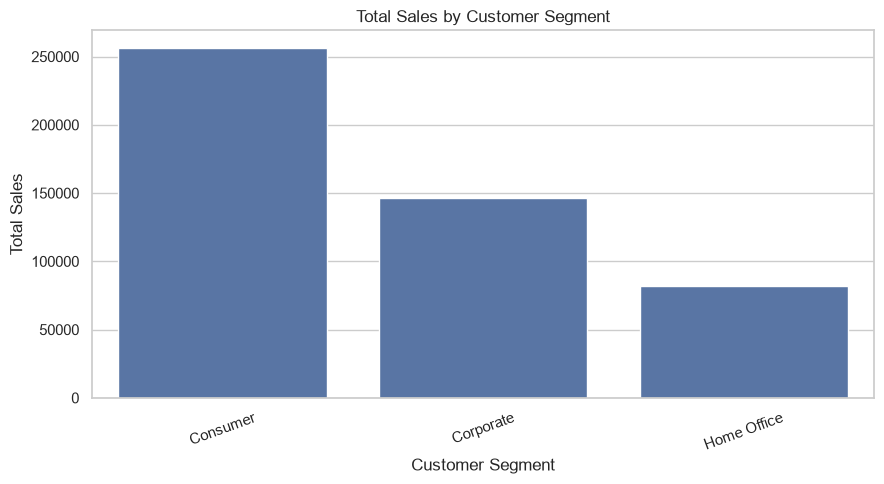

In [12]:
segment_sales = (
    df.groupby("Customer_Segment")["Total_Sales"]
      .sum()
      .sort_values(ascending=False)
)
display(segment_sales)

plt.figure(figsize=(9, 5))
sns.barplot(x=segment_sales.index, y=segment_sales.values)
plt.title("Total Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 10. Analysis 6 — Top 10 Products by Sales

**Question:** Which products generate the highest total sales?

**Business use:** Identifies best-selling products by sales value. This is different from ranking products by profit.

Product_Name
Standing Desk Converter          46614.22
Ergonomic Office Chair           45405.15
Corner L-Shaped Desk             41070.48
Mesh Back Task Chair             38179.77
Wireless Bluetooth Headphones    28258.70
Mechanical Gaming Keyboard       24072.42
Filing Cabinet 3-Drawer          23108.01
Folding Table Portable           18663.13
Portable External SSD 1TB        18065.30
Bookshelf 5-Tier                 17741.59
Name: Total_Sales, dtype: float64

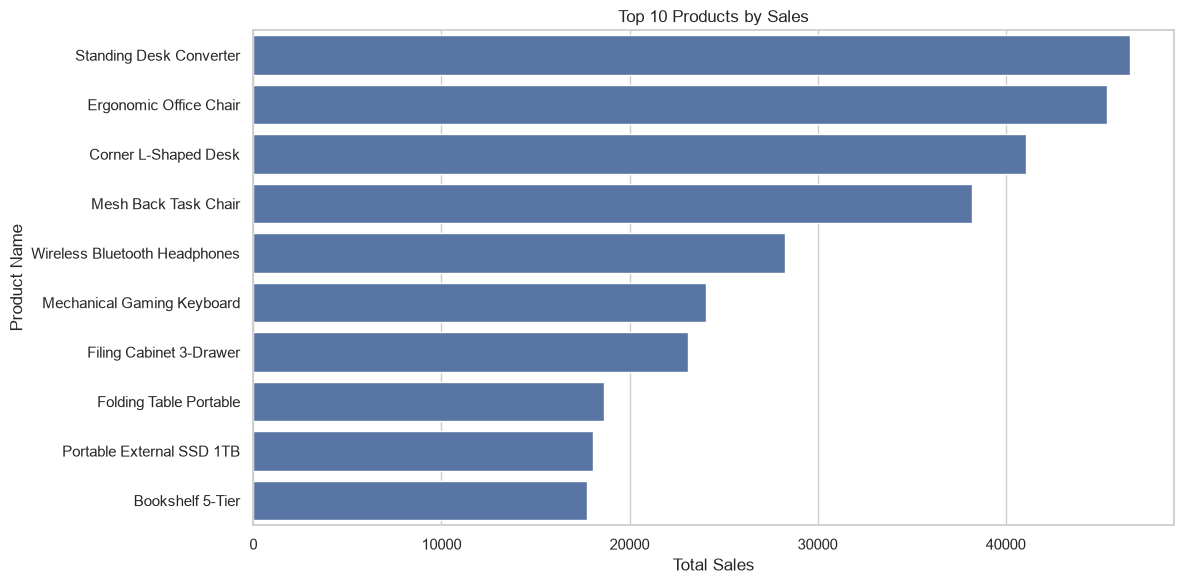

In [13]:
top_products_sales = (
    df.groupby("Product_Name")["Total_Sales"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)
display(top_products_sales)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_products_sales.values, y=top_products_sales.index)
plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()

## 11. Analysis 7 — Discount vs Profit

**Question:** How are discount percentages related to profit?

**Business use:** Helps investigate whether higher discounts are associated with lower or higher profit.

**Note:** A relationship in this chart does not by itself prove that discounts cause a change in profit.

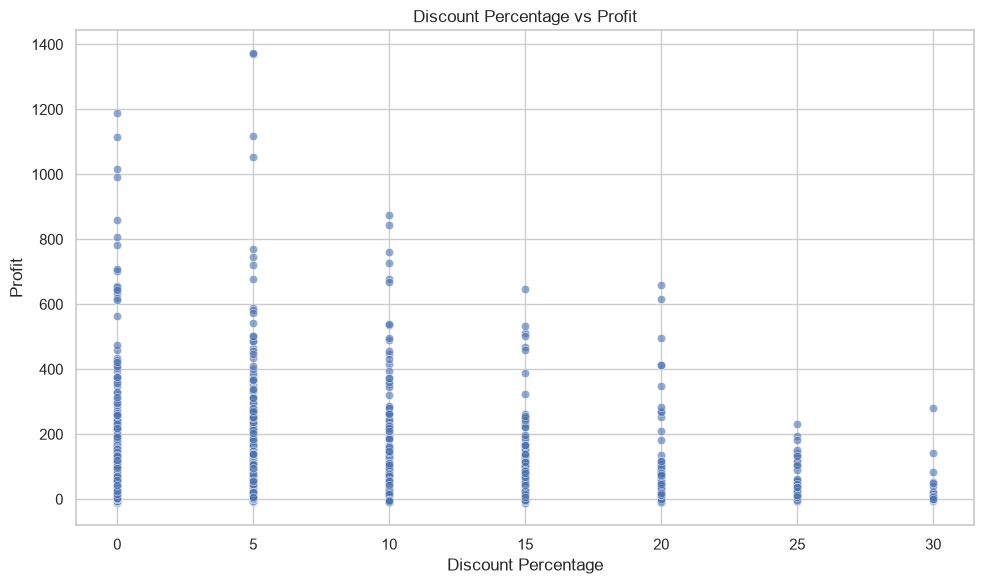

,Average_Profit,Total_Profit,Order_Count
Discount_Percent,,,
0,100.805726,50705.28,503
5,94.526947,46129.15,488
10,74.339752,32932.51,443
15,52.894551,16503.10,312
20,55.061420,9305.38,169
25,38.337015,2568.58,67
30,40.462222,728.32,18


In [14]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Discount_Percent", y="Profit", alpha=0.6)
plt.title("Discount Percentage vs Profit")
plt.xlabel("Discount Percentage")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()

discount_profit = (
    df.groupby("Discount_Percent")
      .agg(
          Average_Profit=("Profit", "mean"),
          Total_Profit=("Profit", "sum"),
          Order_Count=("Order_ID", "count")
      )
      .sort_index()
)
display(discount_profit)

## 12. Analysis 8 — Sales by Payment Method

**Question:** Which payment method accounts for the highest total sales?

**Business use:** Helps understand customer payment preferences and sales contribution by payment method.

Payment_Method
Credit Card         192717.89
PayPal              143112.87
Cash on Delivery     77129.54
Bank Transfer        71599.04
Name: Total_Sales, dtype: float64

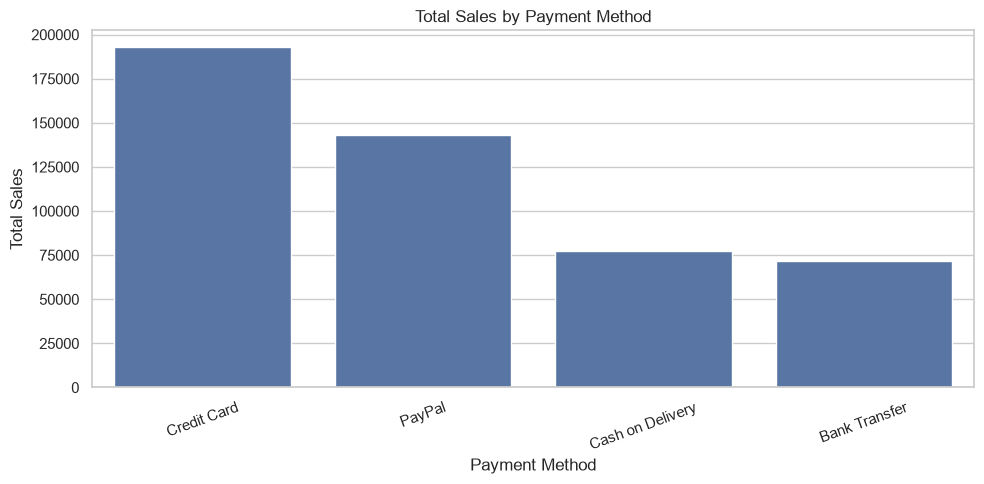

In [15]:
payment_sales = (
    df.groupby("Payment_Method")["Total_Sales"]
      .sum()
      .sort_values(ascending=False)
)
display(payment_sales)

plt.figure(figsize=(10, 5))
sns.barplot(x=payment_sales.index, y=payment_sales.values)
plt.title("Total Sales by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Sales")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 13. Analysis 9 — Quantity Sold by Product Category

**Question:** Which product category has the highest quantity sold?

**Business use:** Compares sales volume across product categories. Quantity sold and sales value are different measures.

Product_Category
Technology                2017
Furniture                 1806
Office Supplies           1741
Clothing & Accessories    1551
Name: Quantity, dtype: int64

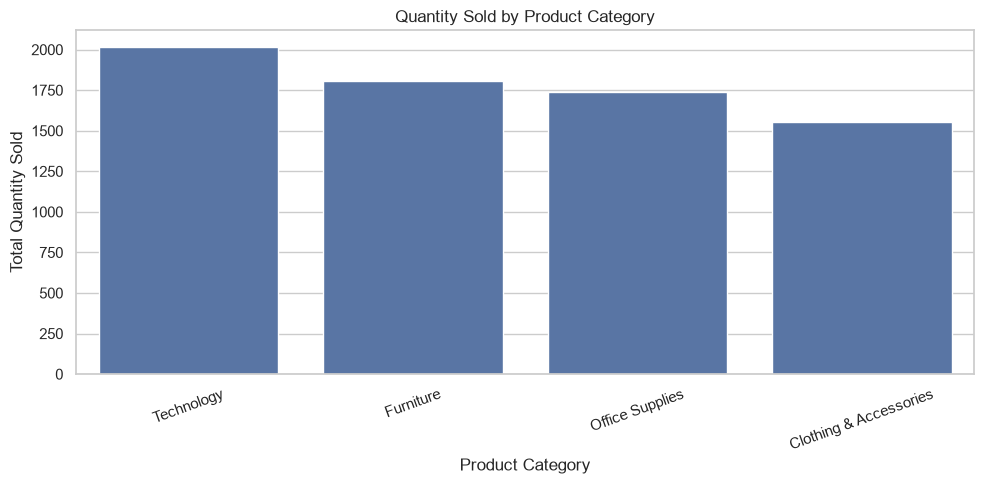

In [16]:
category_quantity = (
    df.groupby("Product_Category")["Quantity"]
      .sum()
      .sort_values(ascending=False)
)
display(category_quantity)

plt.figure(figsize=(10, 5))
sns.barplot(x=category_quantity.index, y=category_quantity.values)
plt.title("Quantity Sold by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 14. Analysis 10 — Shipping Cost vs Profit

**Question:** How are shipping costs related to profit?

**Business use:** Helps explore whether orders with higher shipping costs tend to have different profit values.

**Note:** This is an exploratory relationship, not proof of causation.

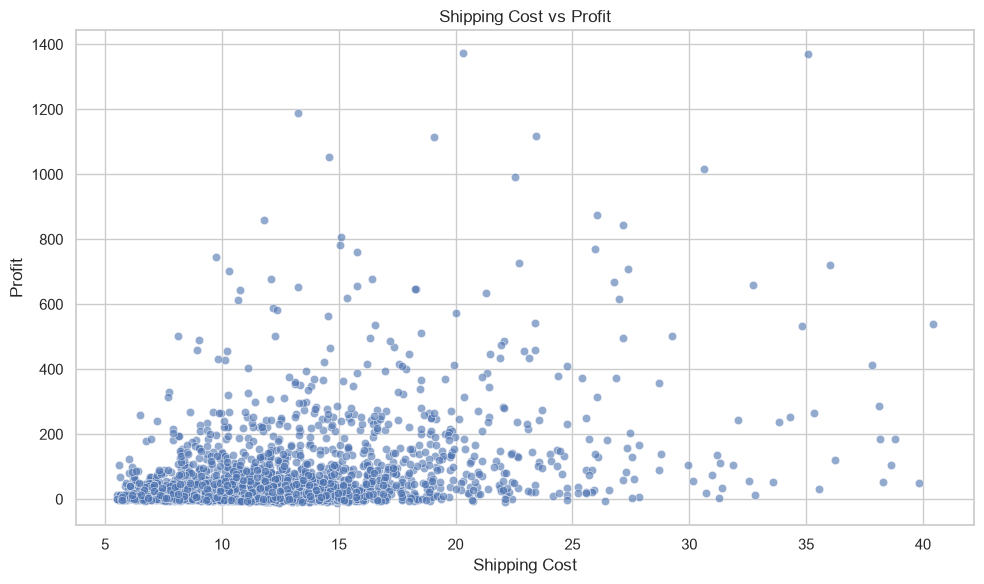

,Shipping_Cost,Profit
Shipping_Cost,1.000000,0.363832
Profit,0.363832,1.000000


In [17]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Shipping_Cost", y="Profit", alpha=0.6)
plt.title("Shipping Cost vs Profit")
plt.xlabel("Shipping Cost")
plt.ylabel("Profit")
plt.tight_layout()
plt.show()

shipping_summary = df[["Shipping_Cost", "Profit"]].corr()
display(shipping_summary)

## 15. Overall Business Summary

The code below prints a few key results from the dataset. Use these results, along with the charts, to write your final project observations.

In [18]:
print("TOTAL SALES:", round(df["Total_Sales"].sum(), 2))
print("TOTAL PROFIT:", round(df["Profit"].sum(), 2))
print("TOTAL QUANTITY SOLD:", int(df["Quantity"].sum()))

print("\\nHighest sales region:")
print(region_sales.idxmax(), "—", round(region_sales.max(), 2))

print("\\nMost profitable product:")
print(top_products_profit.idxmax(), "—", round(top_products_profit.max(), 2))

print("\\nMost profitable product category:")
print(category_profit.idxmax(), "—", round(category_profit.max(), 2))

print("\\nHighest sales customer segment:")
print(segment_sales.idxmax(), "—", round(segment_sales.max(), 2))

print("\\nHighest sales payment method:")
print(payment_sales.idxmax(), "—", round(payment_sales.max(), 2))

TOTAL SALES: 484559.34
TOTAL PROFIT: 158872.32
TOTAL QUANTITY SOLD: 7115
\nHighest sales region:
Europe — 137006.2
\nMost profitable product:
Ergonomic Office Chair — 15104.58
\nMost profitable product category:
Furniture — 81171.57
\nHighest sales customer segment:
Consumer — 256287.74
\nHighest sales payment method:
Credit Card — 192717.89


## Conclusion

**Key findings from the analysis**

- Total sales are 484.56K with a profit of 158.87K (profit margin 32.79%) across 2,000 orders and 1,534 customers.
- Furniture is the top category with 52.9% of sales, while Office Supplies has the lowest margin (17.1%).
- Europe and North America generate about 56% of sales. South America and Middle East & Africa contribute about 9.5% each.
- Consumer is the largest segment (52.9% of sales).
- Credit Card is the most used payment method (39.8% of sales).
- Profit margin drops from 38.7% with no discount to 17.6% when the discount is above 20%.
- Sales are stable across years. 2025 (164.9K) is 6.3% higher than 2024 (155.2K), and October is the strongest month.

**Next steps:** Use these findings to build the Power BI dashboard.